# PathSnap Review 1 - LightGBM, six features
Uses the supplied processed ZIP and its fixed trip folds. Labels are geometric weak labels; scores are not independently verified road-matching accuracy.


## 1. Setup


In [10]:
%pip -q install 'numpy>=1.26,<3' 'pandas>=2.2,<4' 'scikit-learn>=1.4,<2' 'lightgbm>=4.3,<5'


In [2]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')
PROJECT_ROOT = Path("/content/drive/MyDrive")
ZIP_PATH = PROJECT_ROOT / "PathSnap_ip" / "PathSnap_shared6.zip"
OUTPUT_DIR = PROJECT_ROOT / "output" / "LightGBM"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Input:', ZIP_PATH)
print('Output:', OUTPUT_DIR)




Mounted at /content/drive
Input: /content/drive/MyDrive/PathSnap_ip/PathSnap_shared6.zip
Output: /content/drive/MyDrive/output/LightGBM


In [3]:
import io
import json
import zipfile
from dataclasses import dataclass
from time import perf_counter
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss, confusion_matrix
from lightgbm import LGBMClassifier
from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
FEATURES = ['distance_m', 'distance_rank', 'heading_difference_deg',
            'projection_fraction', 'segment_length_m', 'displacement_m']
METRICS = ['Accuracy', 'Precision', 'Recall', 'F1', 'Log Loss', 'Top-1 Accuracy',
           'Candidate Miss Rate', 'Train Time', 'Inference Time']
PARAMS = dict(
    objective='binary', n_estimators=200, learning_rate=0.05,
    num_leaves=31, max_depth=-1, min_child_samples=50, reg_lambda=1.0,
    subsample=1.0, colsample_bytree=1.0, random_state=RANDOM_STATE,
    n_jobs=4, deterministic=True, force_col_wise=True, verbosity=-1,
)
@dataclass
class Dataset:
    candidates: pd.DataFrame
    observations: pd.DataFrame


## 2. Load and check the processed data


In [4]:
def load_split(archive, split):
    with np.load(io.BytesIO(archive.read(f'{split}_features.npz')), allow_pickle=False) as data:
        X = data['X']
        if X.ndim != 2 or X.shape[1] != len(FEATURES) or not np.isfinite(X).all():
            raise ValueError(f'{split}: expected six finite feature columns')
        candidates = pd.DataFrame(X, columns=FEATURES)
        for column in ['trip_id', 'observation_id', 'arc_id', 'label']:
            candidates[column] = data[column]
    observations = pd.read_csv(io.BytesIO(archive.read(f'{split}_observations.csv.gz')),
                               compression='gzip', dtype={'trip_id': str})
    if observations.observation_id.duplicated().any():
        raise ValueError(f'{split}: duplicate observation IDs')
    if candidates.duplicated(['observation_id', 'arc_id']).any():
        raise ValueError(f'{split}: duplicate candidates')
    assert set(candidates.label.unique()) == {0, 1}
    linked = observations.set_index('observation_id').loc[candidates.observation_id]
    assert np.array_equal(candidates.trip_id.to_numpy(), linked.trip_id.to_numpy())
    assert np.array_equal(candidates.label.to_numpy(),
                          (candidates.arc_id.to_numpy() == linked.reference_arc_id.to_numpy()).astype(np.int8))
    counts = candidates.groupby('observation_id').size().reindex(observations.observation_id, fill_value=0).to_numpy()
    positives = candidates.groupby('observation_id').label.sum().reindex(observations.observation_id, fill_value=0).to_numpy()
    assert (positives <= 1).all()
    assert np.array_equal(counts, observations.candidate_count.to_numpy())
    assert np.array_equal(positives > 0, observations.reference_present.to_numpy())
    return Dataset(candidates, observations)


with zipfile.ZipFile(ZIP_PATH) as archive:
    protocol = json.loads(archive.read('shared_protocol.json'))
    feature_schema = json.loads(archive.read('feature_schema.json'))
    assert protocol['features'] == FEATURES == [row['name'] for row in feature_schema]
    train = load_split(archive, 'train')
    student_test = load_split(archive, 'student_test')
    folds = pd.read_csv(io.BytesIO(archive.read('fold_assignments.csv')), dtype={'trip_id': str})
    assert len(folds) == 80 and not folds.trip_id.duplicated().any()
    assert set(folds.fold) == {1, 2, 3, 4, 5}
    assert set(folds.trip_id) == set(train.observations.trip_id)
    trip_folds = folds.set_index('trip_id').fold
    row_folds = train.candidates.trip_id.map(trip_folds).to_numpy()
    fold_indices = {}
    for fold in range(1, 6):
        with np.load(io.BytesIO(archive.read(f'fold_{fold}_indices.npz')), allow_pickle=False) as indices:
            fit_idx, valid_idx = indices['fit_idx'], indices['valid_idx']
        assert np.array_equal(fit_idx, np.flatnonzero(row_folds != fold))
        assert np.array_equal(valid_idx, np.flatnonzero(row_folds == fold))
        assert not set(train.candidates.trip_id.iloc[fit_idx]) & set(train.candidates.trip_id.iloc[valid_idx])
        fold_indices[fold] = (fit_idx, valid_idx)

assert train.observations.trip_id.nunique() == 80
assert student_test.observations.trip_id.nunique() == 10
assert not set(train.observations.trip_id) & set(student_test.observations.trip_id)
display(pd.DataFrame(feature_schema))
counts = pd.DataFrame([
    dict(Split=name, Trips=data.observations.trip_id.nunique(), Observations=len(data.observations),
         Candidates=len(data.candidates), Positives=int(data.candidates.label.sum()),
         Candidate_misses=int((~data.observations.reference_present).sum()),
         Zero_candidates=int((data.observations.candidate_count == 0).sum()))
    for name, data in [('train', train), ('student_test', student_test)]
])
display(counts)
# Tree training uses the raw six features; the packaged scalers are unused.


,name,definition,rationale
0,distance_m,Shortest projected GPS-to-segment distance (me...,Measures spatial compatibility.
1,distance_rank,1-based distance rank; equal distances break b...,Expresses relative proximity among candidates.
2,heading_difference_deg,Absolute wrapped movement/segment heading diff...,Distinguishes opposite travel directions.
3,projection_fraction,Clipped fraction along segment of the perpendi...,Identifies endpoint and interior projections.
4,segment_length_m,Length of the directed straight segment (metres).,Distinguishes short connectors from long roads.
5,displacement_m,Projected displacement from the preceding reta...,Describes movement magnitude and GPS noise.


,Split,Trips,Observations,Candidates,Positives,Candidate_misses,Zero_candidates
0,train,80,208417,1241756,185349,23068,13604
1,student_test,10,19160,125525,19112,48,0


## 3. Evaluation
F1 is positive-class F1. Rates are fractions, times are seconds, and Top-1 includes all observations, including candidate misses.


In [5]:
def evaluate_predictions(dataset, probabilities, train_seconds=0.0, inference_seconds=0.0):
    c, obs = dataset.candidates, dataset.observations
    p = np.asarray(probabilities, dtype=np.float64)
    if p.shape != (len(c),) or not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError("Expected one finite probability in [0, 1] per candidate")
    if c.empty:
        raise ValueError("No candidate rows in evaluation partition; classification metrics undefined")
    y, pred = c.label.to_numpy(), (p >= 0.5).astype(np.int8)
    scored = c[["observation_id", "arc_id", "distance_rank"]].copy()
    scored["probability"] = p
    best = scored.sort_values(["observation_id", "probability", "distance_rank", "arc_id"],
                              ascending=[True, False, True, True], kind="stable").drop_duplicates("observation_id")
    per_obs = obs.merge(best[["observation_id", "arc_id", "probability"]], on="observation_id", how="left", validate="one_to_one")
    per_obs.rename(columns={"arc_id": "predicted_arc_id", "probability": "predicted_probability"}, inplace=True)
    per_obs["top1_correct"] = per_obs.predicted_arc_id == per_obs.reference_arc_id
    covered = per_obs.reference_present.astype(bool)
    matrix = confusion_matrix(y, pred, labels=[0, 1])
    scores = dict(zip(METRICS, [
        float(accuracy_score(y, pred)), float(precision_score(y, pred, zero_division=0)),
        float(recall_score(y, pred, zero_division=0)), float(f1_score(y, pred, zero_division=0)),
        float(log_loss(y, np.column_stack([1 - p, p]), labels=[0, 1])),
        float(per_obs.top1_correct.mean()), float((~covered).mean()),
        float(train_seconds), float(inference_seconds),
    ]))
    scores.update({"Macro F1": float(f1_score(y, pred, average="macro", labels=[0, 1], zero_division=0)),
                   "Top-1 Accuracy (covered)": float(per_obs.loc[covered, "top1_correct"].mean()) if covered.any() else None,
                   "Observations": len(obs), "Candidates": len(c),
                   "Candidate Miss Count": int((~covered).sum()),
                   "Zero Candidate Observations": int((per_obs.candidate_count == 0).sum())})
    return scores, matrix, per_obs


## 4. Five-fold cross-validation


In [6]:
oof = np.full(len(train.candidates), np.nan)
fold_results = []

for fold, (fit_idx, valid_idx) in fold_indices.items():
    fit = train.candidates.iloc[fit_idx]
    valid_trips = trip_folds.index[trip_folds == fold]
    valid = Dataset(train.candidates.iloc[valid_idx],
                    train.observations.loc[train.observations.trip_id.isin(valid_trips)])
    assert set(fit.label.unique()) == {0, 1}
    model = LGBMClassifier(**PARAMS)
    start = perf_counter()
    model.fit(fit[FEATURES], fit.label)
    train_time = perf_counter() - start
    start = perf_counter()
    probabilities = model.predict_proba(valid.candidates[FEATURES])[:, list(model.classes_).index(1)]
    inference_time = perf_counter() - start
    scores, _, _ = evaluate_predictions(valid, probabilities, train_time, inference_time)
    scores.update(Fold=fold, Fit_Trips=fit.trip_id.nunique(), Validation_Trips=len(valid_trips))
    fold_results.append(scores)
    oof[valid_idx] = probabilities
    print(f"Fold {fold}: F1={scores['F1']:.4f}, Top-1={scores['Top-1 Accuracy']:.4f}")

assert np.isfinite(oof).all()
cv_metrics = pd.DataFrame(fold_results)
cv_summary = cv_metrics[METRICS + ['Macro F1', 'Top-1 Accuracy (covered)']].agg(['mean', 'std']).T
cv_summary.index.name = 'Metric'
cv_pooled, cv_matrix, _ = evaluate_predictions(
    train, oof, cv_metrics['Train Time'].sum(), cv_metrics['Inference Time'].sum()
)
display(cv_metrics)
display(cv_summary.assign(**{'Mean +/- SD': cv_summary.apply(lambda r: f"{r['mean']:.6f} +/- {r['std']:.6f}", axis=1)}))
display(pd.DataFrame(cv_matrix, index=['actual_0', 'actual_1'], columns=['predicted_0', 'predicted_1']))


Fold 1: F1=0.7442, Top-1=0.4531
Fold 2: F1=0.7574, Top-1=0.7628
Fold 3: F1=0.7592, Top-1=0.7693
Fold 4: F1=0.8331, Top-1=0.7872
Fold 5: F1=0.7851, Top-1=0.7827


,Accuracy,Precision,Recall,F1,Log Loss,Top-1 Accuracy,Candidate Miss Rate,Train Time,Inference Time,Macro F1,Top-1 Accuracy (covered),Observations,Candidates,Candidate Miss Count,Zero Candidate Observations,Fold,Fit_Trips,Validation_Trips
0,0.935210,0.753909,0.734810,0.744237,0.156066,0.453110,0.413778,23.550235,2.693490,0.853572,0.772933,41747,190771,17274,12901,1,65,15
1,0.925518,0.768690,0.746436,0.757400,0.172312,0.762764,0.016867,18.544565,2.203950,0.856703,0.775850,41739,263447,704,303,2,64,16
2,0.915557,0.774784,0.744160,0.759163,0.182976,0.769293,0.001030,20.488571,3.344537,0.853983,0.770087,41737,233127,43,0,3,64,16
3,0.955763,0.842284,0.824090,0.833088,0.111778,0.787213,0.097955,17.407961,2.227785,0.903795,0.872698,41417,278883,4057,57,4,64,16
4,0.938053,0.806915,0.764459,0.785114,0.148505,0.782727,0.023697,18.242552,2.549248,0.874462,0.801726,41777,275528,990,343,5,63,17


,mean,std,Mean +/- SD
Metric,,,
Accuracy,0.934020,0.015030,0.934020 +/- 0.015030
Precision,0.789316,0.035375,0.789316 +/- 0.035375
Recall,0.762791,0.035909,0.762791 +/- 0.035909
F1,0.775800,0.035285,0.775800 +/- 0.035285
Log Loss,0.154327,0.027347,0.154327 +/- 0.027347
Top-1 Accuracy,0.711022,0.144515,0.711022 +/- 0.144515
Candidate Miss Rate,0.110665,0.173508,0.110665 +/- 0.173508
Train Time,19.646777,2.456859,19.646777 +/- 2.456859
Inference Time,2.603802,0.463945,2.603802 +/- 0.463945


,predicted_0,predicted_1
actual_0,1019075,37332
actual_1,43741,141608


## 5. Final training and student test


In [7]:
model = LGBMClassifier(**PARAMS)
start = perf_counter()
model.fit(train.candidates[FEATURES], train.candidates.label)
train_time = perf_counter() - start
start = perf_counter()
probabilities = model.predict_proba(student_test.candidates[FEATURES])[:, list(model.classes_).index(1)]
inference_time = perf_counter() - start
student_metrics, student_matrix, student_predictions = evaluate_predictions(
    student_test, probabilities, train_time, inference_time
)
model_comparison = pd.DataFrame([
    {'Model': 'LightGBM', **{name: student_metrics[name] for name in METRICS}}
], columns=['Model'] + METRICS)
display(model_comparison)
display(pd.Series(student_metrics, name='Student test'))
display(pd.DataFrame(student_matrix, index=['actual_0', 'actual_1'], columns=['predicted_0', 'predicted_1']))


,Model,Accuracy,Precision,Recall,F1,Log Loss,Top-1 Accuracy,Candidate Miss Rate,Train Time,Inference Time
0,LightGBM,0.942848,0.818347,0.802846,0.810522,0.137463,0.824426,0.002505,23.649672,1.051434


,Student test
Accuracy,0.942848
Precision,0.818347
Recall,0.802846
F1,0.810522
Log Loss,0.137463
Top-1 Accuracy,0.824426
Candidate Miss Rate,0.002505
Train Time,23.649672
Inference Time,1.051434
Macro F1,0.888436


,predicted_0,predicted_1
actual_0,103007,3406
actual_1,3768,15344


## 6. Save outputs


In [8]:
counts.to_csv(OUTPUT_DIR / 'dataset_counts.csv', index=False)
pd.DataFrame(feature_schema).to_csv(OUTPUT_DIR / 'feature_schema.csv', index=False)
folds.to_csv(OUTPUT_DIR / 'fold_assignments.csv', index=False)
cv_metrics.to_csv(OUTPUT_DIR / 'cv_fold_metrics.csv', index=False)
cv_summary.to_csv(OUTPUT_DIR / 'cv_summary.csv')
model_comparison.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)
student_predictions.to_csv(OUTPUT_DIR / 'student_test_predictions.csv.gz', index=False)
model.booster_.save_model(str(OUTPUT_DIR / 'lightgbm_model.txt'))
for name, matrix in [('cv_pooled_confusion_matrix.csv', cv_matrix), ('student_test_confusion_matrix.csv', student_matrix)]:
    pd.DataFrame(matrix, index=['actual_0', 'actual_1'], columns=['predicted_0', 'predicted_1']).to_csv(OUTPUT_DIR / name)

import importlib.metadata
config = dict(parameters=PARAMS, features=FEATURES, input_zip=ZIP_PATH.name,
              random_state=42, folds='Supplied fixed trip folds and candidate indices',
              scaling='Raw features; no scaler required', threshold=.5,
              label_type=protocol['labels'],
              versions={name: importlib.metadata.version(name) for name in
                        ['numpy', 'pandas', 'scikit-learn', 'lightgbm']})
for name, value in [('model_config.json', config), ('student_test_metrics.json', student_metrics),
                    ('cv_pooled_metrics.json', cv_pooled)]:
    (OUTPUT_DIR / name).write_text(json.dumps(value, indent=2, allow_nan=False), encoding='utf-8')
print('Saved:', OUTPUT_DIR)
print('Review 1 complete: LightGBM with six features.')


Saved: /content/drive/MyDrive/output/LightGBM
Review 1 complete: LightGBM with six features.


In [9]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/LightGBM_shared6_results",
    "zip",
    root_dir=OUTPUT_DIR,
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Model,CV Macro F1,CV Macro F1 SD,Student Top-1,Student Macro F1,CV Log Loss,Student Log Loss
0,LightGBM,0.868503,0.021529,0.824426,0.888436,0.154327,0.137463


Showing LightGBM only. Add other result folders for cross-model comparisons.


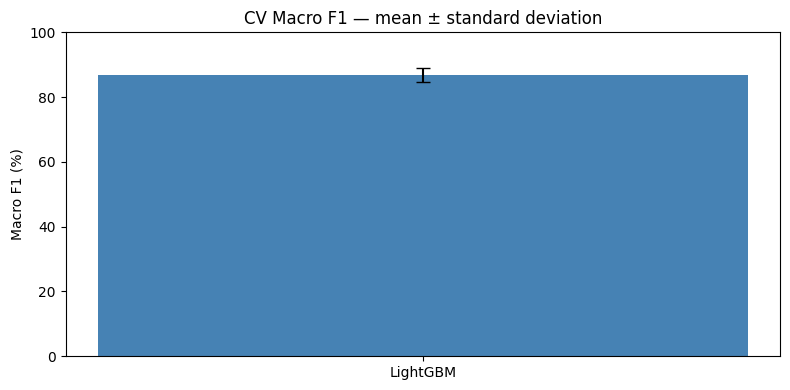

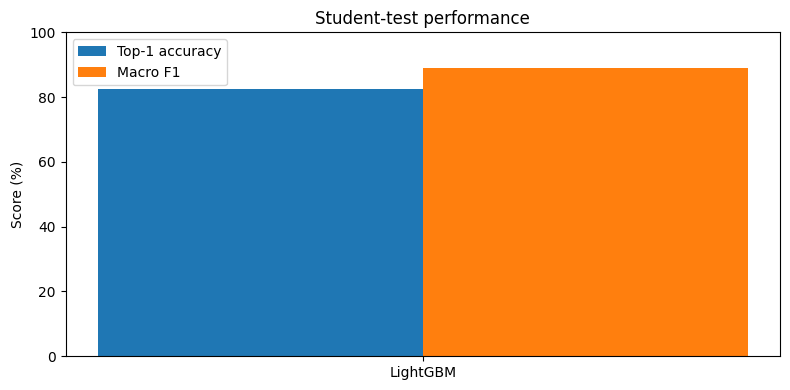

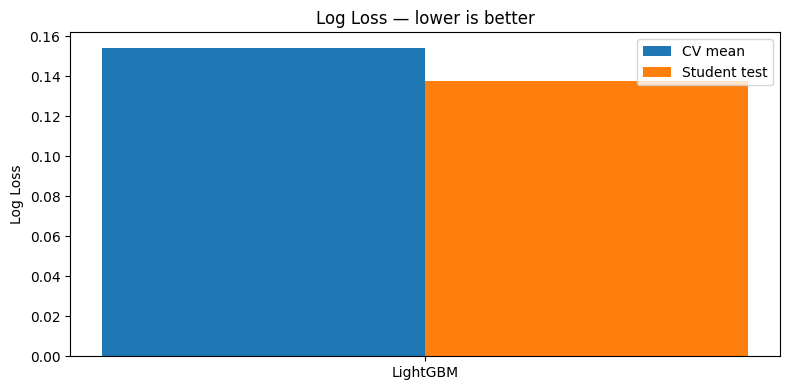

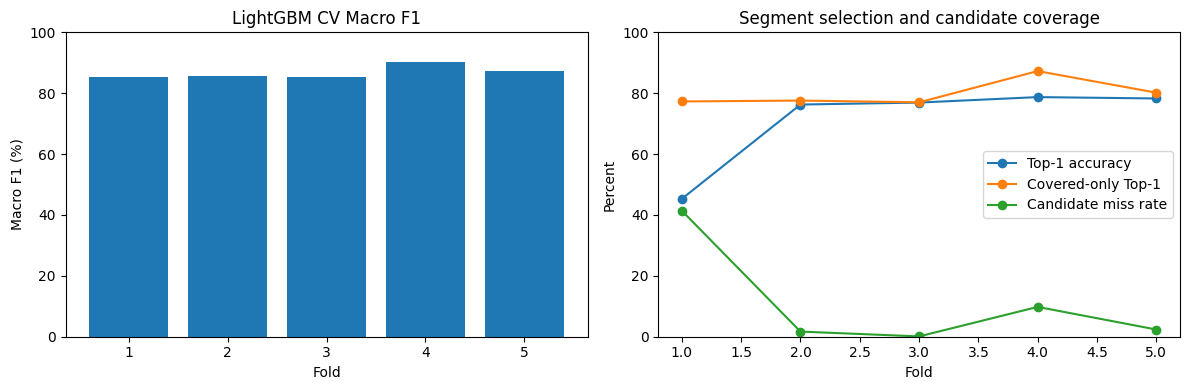

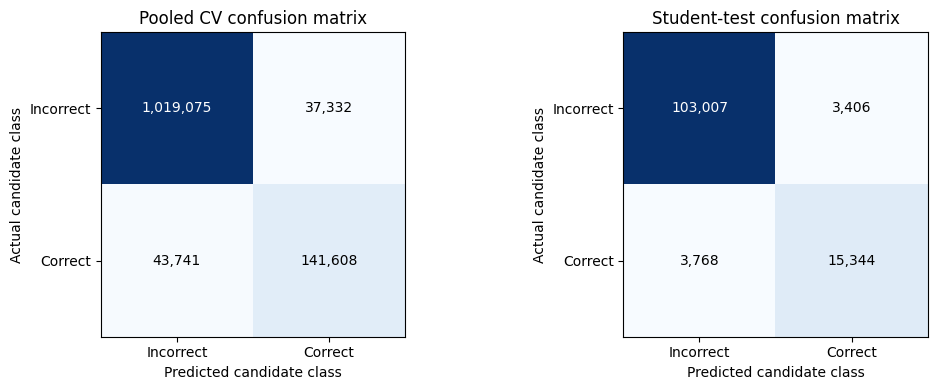

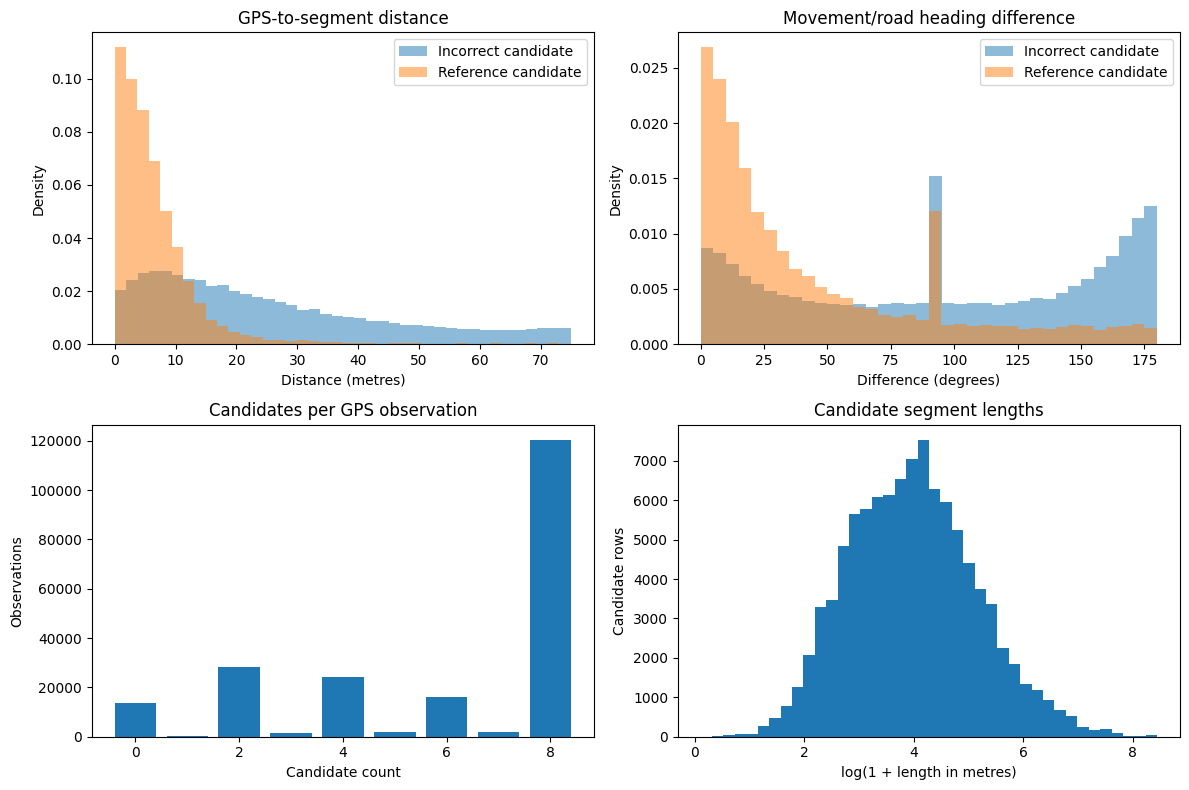

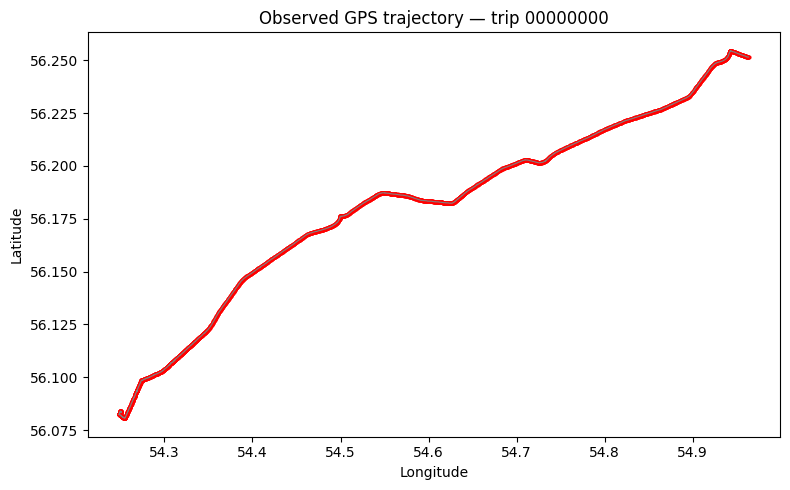

GPS-only map: original road geometry was not found at: /content/drive/MyDrive/PathSnap_raw/Student folder/student_test/00000000
Set RAW_DATA_ROOT to the original folder containing train/ and student_test/ to show road and segment layers.


All plots use actual recorded results or supplied data.
No artificial training/validation loss curves were generated.


In [12]:
%pip -q install matplotlib folium

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium

from pathlib import Path
from IPython.display import display

# Optional: extracted results folders from other models using the same dataset.
OTHER_RESULT_DIRS = [
    # PROJECT_ROOT / "output" / "XGBoost",
    # PROJECT_ROOT / "output" / "ExtraTrees",
]

# Optional: original folder containing train/ and student_test/.
# Needed for road/reference/prediction geometry; otherwise GPS alone is shown.
RAW_DATA_ROOT = PROJECT_ROOT / "PathSnap_raw" / "Student folder"


# 1. Gather actual model results
records = [{
    "Model": "LightGBM",
    "CV Macro F1": cv_summary.loc["Macro F1", "mean"],
    "CV Macro F1 SD": cv_summary.loc["Macro F1", "std"],
    "Student Top-1": student_metrics["Top-1 Accuracy"],
    "Student Macro F1": student_metrics["Macro F1"],
    "CV Log Loss": cv_summary.loc["Log Loss", "mean"],
    "Student Log Loss": student_metrics["Log Loss"],
}]

for directory in OTHER_RESULT_DIRS:
    directory = Path(directory)

    config = json.loads((directory / "model_config.json").read_text())
    feature_order = config.get("features", config.get("feature_order"))
    if feature_order != FEATURES:
        raise ValueError(f"{directory.name}: different feature order")

    other_folds = pd.read_csv(
        directory / "fold_assignments.csv", dtype={"trip_id": str}
    ).sort_values("trip_id").reset_index(drop=True)

    current_folds = folds.sort_values("trip_id").reset_index(drop=True)
    if not other_folds.equals(current_folds):
        raise ValueError(f"{directory.name}: different CV folds")

    summary = pd.read_csv(directory / "cv_summary.csv", index_col=0)
    scores = json.loads((directory / "student_test_metrics.json").read_text())
    comparison = pd.read_csv(directory / "model_comparison.csv")

    records.append({
        "Model": comparison.iloc[0]["Model"],
        "CV Macro F1": summary.loc["Macro F1", "mean"],
        "CV Macro F1 SD": summary.loc["Macro F1", "std"],
        "Student Top-1": scores["Top-1 Accuracy"],
        "Student Macro F1": scores["Macro F1"],
        "CV Log Loss": summary.loc["Log Loss", "mean"],
        "Student Log Loss": scores["Log Loss"],
    })

results_plot = pd.DataFrame(records)
display(results_plot)

if len(results_plot) == 1:
    print("Showing LightGBM only. Add other result folders for cross-model comparisons.")


# 2. CV Macro F1 comparison
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    results_plot["Model"],
    results_plot["CV Macro F1"] * 100,
    yerr=results_plot["CV Macro F1 SD"] * 100,
    capsize=5,
    color="steelblue",
)
ax.set(
    title="CV Macro F1 — mean ± standard deviation",
    ylabel="Macro F1 (%)",
    ylim=(0, 100),
)
plt.tight_layout()
plt.show()


# 3. Student-test Top-1 and Macro F1
x = np.arange(len(results_plot))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    x - 0.2, results_plot["Student Top-1"] * 100,
    width=0.4, label="Top-1 accuracy",
)
ax.bar(
    x + 0.2, results_plot["Student Macro F1"] * 100,
    width=0.4, label="Macro F1",
)
ax.set_xticks(x, results_plot["Model"])
ax.set(title="Student-test performance", ylabel="Score (%)", ylim=(0, 100))
ax.legend()
plt.tight_layout()
plt.show()


# 4. Log Loss comparison
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, results_plot["CV Log Loss"], 0.4, label="CV mean")
ax.bar(x + 0.2, results_plot["Student Log Loss"], 0.4, label="Student test")
ax.set_xticks(x, results_plot["Model"])
ax.set(title="Log Loss — lower is better", ylabel="Log Loss")
ax.legend()
plt.tight_layout()
plt.show()


# 5. LightGBM performance across folds
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(cv_metrics["Fold"], cv_metrics["Macro F1"] * 100)
axes[0].set(
    title="LightGBM CV Macro F1",
    xlabel="Fold", ylabel="Macro F1 (%)", ylim=(0, 100),
)

axes[1].plot(
    cv_metrics["Fold"], cv_metrics["Top-1 Accuracy"] * 100,
    marker="o", label="Top-1 accuracy",
)
axes[1].plot(
    cv_metrics["Fold"], cv_metrics["Top-1 Accuracy (covered)"] * 100,
    marker="o", label="Covered-only Top-1",
)
axes[1].plot(
    cv_metrics["Fold"], cv_metrics["Candidate Miss Rate"] * 100,
    marker="o", label="Candidate miss rate",
)
axes[1].set(
    title="Segment selection and candidate coverage",
    xlabel="Fold", ylabel="Percent", ylim=(0, 100),
)
axes[1].legend()
plt.tight_layout()
plt.show()


# 6. Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, matrix, title in zip(
    axes,
    [cv_matrix, student_matrix],
    ["Pooled CV confusion matrix", "Student-test confusion matrix"],
):
    matrix = np.asarray(matrix)
    ax.imshow(matrix, cmap="Blues")

    for row in range(2):
        for col in range(2):
            ax.text(
                col, row, f"{matrix[row, col]:,}",
                ha="center", va="center",
                color="white" if matrix[row, col] > matrix.max() / 2 else "black",
            )

    ax.set_xticks([0, 1], ["Incorrect", "Correct"])
    ax.set_yticks([0, 1], ["Incorrect", "Correct"])
    ax.set(
        title=title,
        xlabel="Predicted candidate class",
        ylabel="Actual candidate class",
    )

plt.tight_layout()
plt.show()


# 7. Training-data EDA
sample = train.candidates.sample(
    n=min(100_000, len(train.candidates)), random_state=42
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for label, name in [(0, "Incorrect candidate"), (1, "Reference candidate")]:
    rows = sample.loc[sample.label == label]

    axes[0, 0].hist(
        rows.distance_m, bins=40, alpha=0.5,
        density=True, label=name,
    )
    axes[0, 1].hist(
        rows.heading_difference_deg, bins=36, alpha=0.5,
        density=True, label=name,
    )

axes[0, 0].set(
    title="GPS-to-segment distance",
    xlabel="Distance (metres)", ylabel="Density",
)
axes[0, 0].legend()

axes[0, 1].set(
    title="Movement/road heading difference",
    xlabel="Difference (degrees)", ylabel="Density",
)
axes[0, 1].legend()

axes[1, 0].hist(
    train.observations.candidate_count,
    bins=np.arange(-0.5, 9.5, 1),
    rwidth=0.8,
)
axes[1, 0].set(
    title="Candidates per GPS observation",
    xlabel="Candidate count", ylabel="Observations",
)

axes[1, 1].hist(np.log1p(sample.segment_length_m), bins=40)
axes[1, 1].set(
    title="Candidate segment lengths",
    xlabel="log(1 + length in metres)", ylabel="Candidate rows",
)

plt.tight_layout()
plt.show()


# 8. Selected student-test GPS trajectory
trip_id = sorted(student_test.observations.trip_id.unique())[0]
trip_obs = student_predictions.loc[
    student_predictions.trip_id == trip_id
].sort_values("timestamp")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(trip_obs.longitude, trip_obs.latitude, linewidth=0.8, color="gray")
ax.scatter(trip_obs.longitude, trip_obs.latitude, s=4, color="red")
ax.set(
    title=f"Observed GPS trajectory — trip {trip_id}",
    xlabel="Longitude", ylabel="Latitude",
)
plt.tight_layout()
plt.show()


# 9. Folium map with an alternative satellite background
trip_map = folium.Map(
    location=[trip_obs.latitude.mean(), trip_obs.longitude.mean()],
    zoom_start=13,
    tiles=(
        "https://services.arcgisonline.com/ArcGIS/rest/services/"
        "World_Imagery/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Esri, Vantor, Earthstar Geographics, and the GIS User Community",
)

gps_layer = folium.FeatureGroup(name="Observed GPS", show=True)
gps_coords = trip_obs[["latitude", "longitude"]].to_numpy().tolist()
folium.PolyLine(gps_coords, color="red", weight=2).add_to(gps_layer)

step = max(1, len(trip_obs) // 300)
for row in trip_obs.iloc[::step].itertuples():
    folium.CircleMarker(
        location=[row.latitude, row.longitude],
        radius=2,
        color="red",
        fill=True,
        fill_opacity=0.8,
        popup=f"GPS observation {row.observation_id}",
    ).add_to(gps_layer)

gps_layer.add_to(trip_map)

trip_folder = RAW_DATA_ROOT / "student_test" / trip_id
node_path = trip_folder / f"{trip_id}.nodes"
arc_path = trip_folder / f"{trip_id}.arcs"
route_path = trip_folder / f"{trip_id}.route"

if node_path.is_file() and arc_path.is_file():
    nodes = np.loadtxt(node_path, ndmin=2)
    arcs = np.loadtxt(arc_path, dtype=int, ndmin=2)

    def add_segments(ids, name, color, weight, show=True):
        ids = np.unique(np.asarray(ids, dtype=int))

        if len(ids) and (ids.min() < 0 or ids.max() >= len(arcs)):
            raise ValueError(f"{name}: arc IDs do not match this network")

        layer = folium.FeatureGroup(name=name, show=show)

        for arc_id in ids:
            coordinates = nodes[arcs[arc_id]][:, [1, 0]].tolist()
            folium.PolyLine(
                coordinates,
                color=color,
                weight=weight,
                tooltip=f"Arc {arc_id}",
            ).add_to(layer)

        layer.add_to(trip_map)

    candidate_ids = student_test.candidates.loc[
        student_test.candidates.trip_id == trip_id, "arc_id"
    ].unique()
    add_segments(
        candidate_ids, "Candidate roads", "gray", 1, show=False
    )

    if route_path.is_file():
        reference_ids = np.loadtxt(route_path, dtype=int, ndmin=1)
        reference_name = "Supplied reference route"
    else:
        reference_ids = trip_obs.reference_arc_id.to_numpy()
        reference_name = "Derived reference segments"

    add_segments(reference_ids, reference_name, "lime", 5)

    predicted_ids = (
        trip_obs.predicted_arc_id.dropna().astype(int).to_numpy()
    )
    add_segments(
        predicted_ids, "LightGBM selected segments", "cyan", 3
    )

    print("Map: red = GPS, green = reference, cyan = model selections.")
else:
    print(
        "GPS-only map: original road geometry was not found at:",
        trip_folder,
    )
    print(
        "Set RAW_DATA_ROOT to the original folder containing "
        "train/ and student_test/ to show road and segment layers."
    )

trip_map.fit_bounds([
    [trip_obs.latitude.min(), trip_obs.longitude.min()],
    [trip_obs.latitude.max(), trip_obs.longitude.max()],
])

folium.LayerControl().add_to(trip_map)
display(trip_map)

print("All plots use actual recorded results or supplied data.")
print("No artificial training/validation loss curves were generated.")